#### **MatchLens: Substitution Impact & Player Influence Analysis**
This notebook analyzes tactical changes by tracking post-substitution event windows (+5, +10, +15 minutes) and aggregates player involvement metrics (shots, cards, substitutions) for Match ID `18243`.

#### **Imports & Setup**

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import plotly.express as px

# Ensure root directory is in sys.path
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))

from src.transformer import MatchLensTransformer

# Initialize Transformer
transformer = MatchLensTransformer(raw_data_dir="../data/raw")
MATCH_ID = 18243

# Load and transform events
df_raw = transformer.load_match_events(match_id=MATCH_ID)
df_events = transformer.engineer_features(df_raw)

print(f"Data loaded successfully. Total events: {len(df_events)}")

Data loaded successfully. Total events: 4708


#### **Module C: Substitution Impact Analysis**

In [2]:
# Filter for substitution events
df_subs = df_events[df_events['is_substitution'] == True].copy()

print(f"Total substitutions recorded in Match {MATCH_ID}: {len(df_subs)}")
if not df_subs.empty:
    display(df_subs[['minute', 'team', 'player', 'sub_replacement']])
    
    # Post-Substitution Window Analysis: Tracking activity within 15 minutes after a substitution
    sub_impact_records = []
    
    for _, sub in df_subs.iterrows():
        sub_minute = sub['minute']
        sub_team = sub['team']
        sub_player = sub['player']
        replacement = sub['sub_replacement']
        
        # Events by the same team in the subsequent 15-minute window
        window_events = df_events[
            (df_events['team'] == sub_team) & 
            (df_events['minute'] > sub_minute) & 
            (df_events['minute'] <= sub_minute + 15)
        ]
        
        shots_in_window = len(window_events[window_events['type'] == 'Shot'])
        goals_in_window = len(window_events[window_events['is_goal'] == True])
        
        sub_impact_records.append({
            'sub_minute': sub_minute,
            'team': sub_team,
            'player_off': sub_player,
            'player_on': replacement,
            'shots_next_15m': shots_in_window,
            'goals_next_15m': goals_in_window
        })
        
    df_sub_impact = pd.DataFrame(sub_impact_records)
    print("\nPost-Substitution Activity Window (+15 min):")
    display(df_sub_impact)
else:
    print("No substitutions recorded in this match sample.")

Total substitutions recorded in Match 18243: 6


,minute,team,player,sub_replacement
1969,45,Atlético Madrid,Augusto Matías Fernández,Yannick Ferreira Carrasco
2109,51,Real Madrid,Daniel Carvajal Ramos,Danilo Luiz da Silva
2763,71,Real Madrid,Toni Kroos,Francisco Román Alarcón Suárez
2912,76,Real Madrid,Karim Benzema,Lucas Vázquez Iglesias
4273,108,Atlético Madrid,Filipe Luís Kasmirski,Lucas Hernández Pi
4418,115,Atlético Madrid,Jorge Resurrección Merodio,Thomas Teye Partey



Post-Substitution Activity Window (+15 min):


,sub_minute,team,player_off,player_on,shots_next_15m,goals_next_15m
0,45,Atlético Madrid,Augusto Matías Fernández,Yannick Ferreira Carrasco,6,0
1,51,Real Madrid,Daniel Carvajal Ramos,Danilo Luiz da Silva,3,0
2,71,Real Madrid,Toni Kroos,Francisco Román Alarcón Suárez,5,0
3,76,Real Madrid,Karim Benzema,Lucas Vázquez Iglesias,6,0
4,108,Atlético Madrid,Filipe Luís Kasmirski,Lucas Hernández Pi,3,3
5,115,Atlético Madrid,Jorge Resurrección Merodio,Thomas Teye Partey,4,3


#### **Module D: Player-Influence & Match-Flow Analysis**

Top 10 Most Involved Players:


,team,player,total_actions,shots,goals,cards
5,Atlético Madrid,Gabriel Fernández Arenas,354,2,1,1
7,Atlético Madrid,Jorge Resurrección Merodio,352,3,0,0
4,Atlético Madrid,Filipe Luís Kasmirski,278,0,0,0
24,Real Madrid,Luka Modrić,248,1,0,0
0,Atlético Madrid,Antoine Griezmann,244,7,1,0
14,Real Madrid,Carlos Henrique Casimiro,232,2,0,1
25,Real Madrid,Marcelo Vieira da Silva Júnior,232,2,1,0
19,Real Madrid,Gareth Frank Bale,211,10,1,0
15,Real Madrid,Cristiano Ronaldo dos Santos Aveiro,191,7,1,0
8,Atlético Madrid,Juan Francisco Torres Belén,187,2,0,0


C:\Users\tohiba\AppData\Local\Temp\ipykernel_14068\967721253.py:24: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  match_flow = df_events.groupby(['match_flow_bin', 'team']).size().reset_index(name='event_volume')


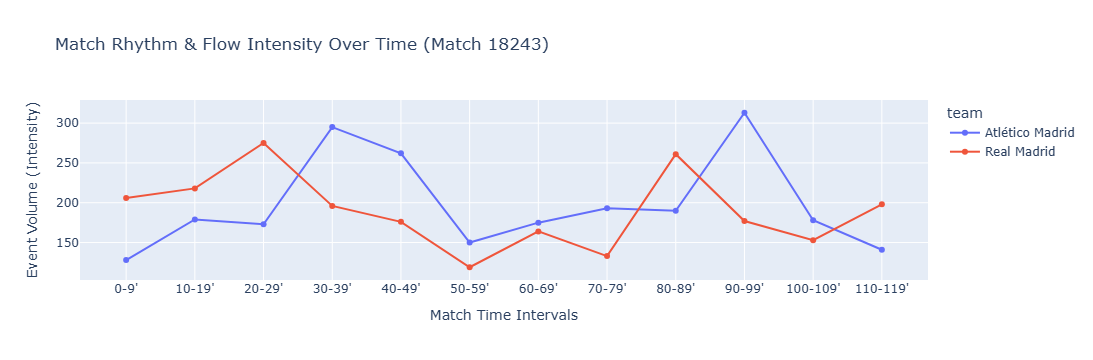

In [3]:
# Aggregate player-level involvement (shots, cards, substitutions)
df_players = df_events.groupby(['team', 'player']).agg(
    total_actions=('event_id', 'count'),
    shots=('type', lambda x: (x == 'Shot').sum()),
    goals=('is_goal', 'sum'),
    cards=('is_card', 'sum')
).reset_index()

# Filter out null players (team-level or unassigned events) and sort by total involvement
df_players = df_players[df_players['player'].notna()]
df_players = df_players.sort_values(by='total_actions', ascending=False)

print("Top 10 Most Involved Players:")
display(df_players.head(10))

# Match Flow: Event Volume by 10-Minute Intervals
df_events['match_flow_bin'] = pd.cut(
    df_events['minute'], 
    bins=range(0, 121, 10), 
    right=False, 
    labels=[f"{i}-{i+9}'" for i in range(0, 120, 10)]
)

match_flow = df_events.groupby(['match_flow_bin', 'team']).size().reset_index(name='event_volume')

fig_flow = px.line(
    match_flow, 
    x='match_flow_bin', 
    y='event_volume', 
    color='team',
    markers=True,
    title=f"Match Rhythm & Flow Intensity Over Time (Match {MATCH_ID})",
    labels={'match_flow_bin': 'Match Time Intervals', 'event_volume': 'Event Volume (Intensity)'}
)
fig_flow.show()

#### **Module E: Advanced Match Analytics & Player Leaderboards**

In [4]:
from src.analytics import MatchLensAnalytics

# 1. Quickly retrieve match KPI summary dictionary
kpi_summary = MatchLensAnalytics.get_match_kpis(df_events)
print("Match KPIs:", kpi_summary)

# 2. Extract Top 10 Most Active Players
df_leaderboard = MatchLensAnalytics.get_player_leaderboard(df_events, top_n=10)
print("\nPlayer Involvement Leaderboard:")
display(df_leaderboard)

# 3. Get Disciplinary Risk Distribution Table
df_discipline_risk = MatchLensAnalytics.get_discipline_distribution(df_events)
print("\nDisciplinary Risk Distribution by Time Interval:")
display(df_discipline_risk)

Match KPIs: {'total_events': 4708, 'total_goals': 10, 'total_cards': 8, 'total_subs': 6}

Player Involvement Leaderboard:


,team,player,total_events,shots,goals,cards
5,Atlético Madrid,Gabriel Fernández Arenas,354,2,1,1
7,Atlético Madrid,Jorge Resurrección Merodio,352,3,0,0
4,Atlético Madrid,Filipe Luís Kasmirski,278,0,0,0
24,Real Madrid,Luka Modrić,248,1,0,0
0,Atlético Madrid,Antoine Griezmann,244,7,1,0
14,Real Madrid,Carlos Henrique Casimiro,232,2,0,1
25,Real Madrid,Marcelo Vieira da Silva Júnior,232,2,1,0
19,Real Madrid,Gareth Frank Bale,211,10,1,0
15,Real Madrid,Cristiano Ronaldo dos Santos Aveiro,191,7,1,0
8,Atlético Madrid,Juan Francisco Torres Belén,187,2,0,0



Disciplinary Risk Distribution by Time Interval:


,time_bucket,team,card_count
0,00-15,Real Madrid,1
1,46-60,Atlético Madrid,1
2,46-60,Real Madrid,1
3,76-90+,Atlético Madrid,1
4,76-90+,Real Madrid,4
